# Candida intermedia FluxFormer evaluation

Evaluate a trained FluxFormer against the separately generated **pFBA test dataset**.

- Inputs: 17 signed exchange lower bounds; targets: 1,971 signed net reaction fluxes.
- Plot training/validation loss and five representative Candida flux diagnostics.
- Report pooled **R², MAE, and RMSE** across every test row and all 1,971 fluxes, including the 17 injected exchange slots.

Run from the repository root. Set the checkpoint and test-data paths below. All test rows are evaluated; the test file is not split again. The simulated metrics describe fidelity to pFBA. The final section separately evaluates measured Candida growth using a trainable MLP and the frozen surrogate.

In [1]:
from datetime import date
import json
from pathlib import Path
import time
import xml.etree.ElementTree as ET

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch

from flux_transformer import FluxTransformer
from generate_candida_intermedia_data import DEFAULT_MODEL, INPUT_EXCHANGES, file_sha256

# Set these to the completed Candida training checkpoint and independent test dataset.
model_name = "CI_100k_d256_h8_l4_ff1024"
CHECKPOINT_PATH = Path("models") / model_name / f"{model_name}_checkpoint.pth"
DATA_PATH = Path("data/2026-11-09_candida_intermedia_test_data_50000_samples.csv")
METADATA_PATH = DATA_PATH.with_suffix(".json")
MODEL_PATH = DEFAULT_MODEL

INFERENCE_BATCH_SIZE = 4  # Full-vocabulary attention; reduce this if GPU memory is limited.
CSV_CHUNK_SIZE = 512
SAVE_PLOTS = False
pic_dir = Path("pics") / date.today().isoformat() / model_name
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)
np.random.seed(42)
print(f"Device: {device}")

Device: cuda


## Load the trained model

Use the shared injected-token architecture and the checkpoint's saved dimensions and reaction ordering. Both ordinary-Huber and normalized-Huber trainer checkpoints use this format; predictions remain in the original flux scale.

In [2]:
checkpoint = torch.load(CHECKPOINT_PATH, map_location="cpu", weights_only=False)
config = checkpoint["config"]
data_info = checkpoint["data_info"]
input_cols = list(data_info["input_cols"])
outputs = list(data_info["output_cols"])
input_token_indices = [int(i) for i in data_info["input_token_indices"]]
if input_cols != list(INPUT_EXCHANGES):
    raise ValueError("Checkpoint input names/order differ from the 17-exchange Candida pilot.")
if len(outputs) != 1971 or int(config["vocab_size"]) != len(outputs):
    raise ValueError("Expected the full 1,971-reaction Candida vocabulary.")
if input_token_indices != [outputs.index(f"{name}_flux") for name in input_cols]:
    raise ValueError("Checkpoint input-to-flux token mapping is inconsistent.")
if list(config["input_token_indices"]) != input_token_indices:
    raise ValueError("Checkpoint config and data_info disagree on injected token indices.")
model = FluxTransformer(
    vocab_size=int(config["vocab_size"]), input_token_indices=input_token_indices,
    d_model=int(config["d_model"]), n_heads=int(config["n_heads"]),
    n_layers=int(config["n_layers"]), d_ff=int(config["d_ff"]),
    dropout=float(config["dropout"]),
)
model.load_state_dict(checkpoint["model_state_dict"], strict=True)
if model.input_token_indices.tolist() != input_token_indices:
    raise ValueError("Saved model buffer differs from checkpoint token metadata.")
model = model.to(device).eval()
train_losses = list(checkpoint.get("train_losses", []))
validation_losses = list(checkpoint.get("test_losses", []))
del checkpoint
print(f"Checkpoint: {CHECKPOINT_PATH}")
print(f"Vocabulary: {len(outputs):,} reactions | Injected inputs: {len(input_cols)}")
print(f"Architecture: d={config['d_model']}, heads={config['n_heads']}, "
      f"layers={config['n_layers']}, ff={config['d_ff']}")
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"Training rows: {data_info['n_train']:,} | Validation rows: {data_info['n_test']:,}")

Checkpoint: models\CI_100k_d256_h8_l4_ff1024\CI_100k_d256_h8_l4_ff1024_checkpoint.pth
Vocabulary: 1,971 reactions | Injected inputs: 17
Architecture: d=256, heads=8, layers=4, ff=1024
Parameters: 3,671,852
Training rows: 80,000 | Validation rows: 20,000


## Load test-data information

Check the CSV schema and generation sidecar before inference. Signed uptake bounds are injected unchanged into their reaction tokens; they are constraints, not achieved uptake fluxes.

In [3]:
test_metadata = json.loads(METADATA_PATH.read_text())
if test_metadata["status"] != "complete" or test_metadata["arguments"]["dataset"] != "test":
    raise ValueError("Use a completed, separately generated test dataset.")
if test_metadata["arguments"]["flux_solver_mode"] != "pfba":
    raise ValueError("This notebook expects pFBA-generated test targets.")
if test_metadata["input_columns"] != input_cols or test_metadata["output_columns"] != outputs:
    raise ValueError("Test-data token names/order differ from the checkpoint.")
if test_metadata["model_sha256"] != file_sha256(MODEL_PATH):
    raise ValueError("Test data were generated from a different SBML model file.")
csv_columns = pd.read_csv(DATA_PATH, nrows=0).columns.tolist()
if csv_columns != input_cols + outputs:
    raise ValueError("CSV columns do not match the checkpoint's input/output schema.")
reaction_ids = [name.removesuffix("_flux") for name in outputs]
sbml_root = ET.parse(MODEL_PATH).getroot()
sbml_reactions = sbml_root.findall(".//{*}listOfReactions/{*}reaction")
reaction_names = {
    reaction.attrib["id"].removeprefix("R_"): reaction.attrib.get("name", "")
    for reaction in sbml_reactions
}
if set(reaction_ids) != set(reaction_names):
    raise ValueError("Checkpoint reaction vocabulary differs from the supplied Candida model.")
print(f"Test data: {DATA_PATH}")
print(f"Rows: {test_metadata['accepted_samples']:,} | Generation seed: {test_metadata['arguments']['seed']}")
print(f"pFBA fraction of optimum: {test_metadata['arguments']['pfba_fraction_of_optimum']}")
print("All test rows will be evaluated, with signed inputs and targets preserved.")

Test data: data\2026-11-09_candida_intermedia_test_data_50000_samples.csv
Rows: 50,000 | Generation seed: 9
pFBA fraction of optimum: 0.999
All test rows will be evaluated, with signed inputs and targets preserved.


## Training and validation loss

The checkpoint calls its held-out training-split history `test_losses`; here it is labeled **validation**. The independent test CSV above was not used to produce these curves.

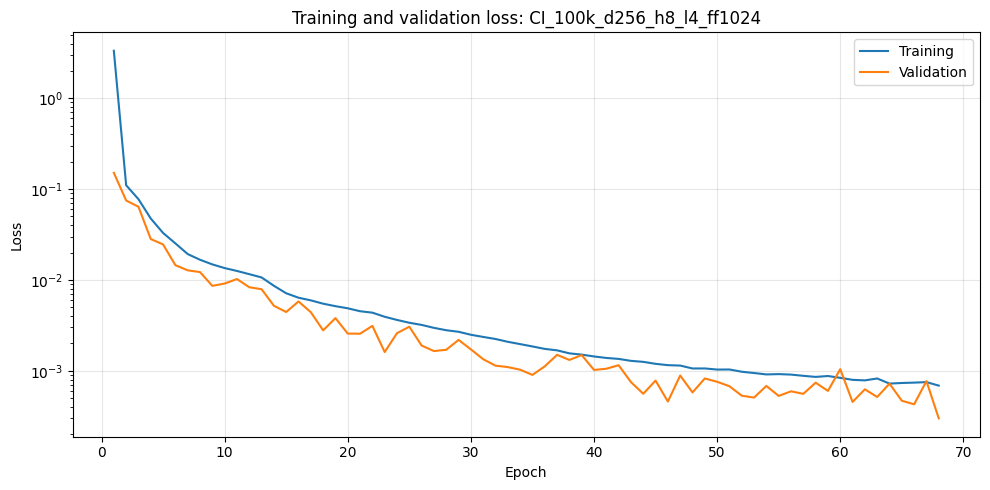

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(np.arange(1, len(train_losses) + 1), train_losses, label="Training")
ax.plot(np.arange(1, len(validation_losses) + 1), validation_losses, label="Validation")
if train_losses and validation_losses and min(train_losses + validation_losses) > 0:
    ax.set_yscale("log")
ax.set(xlabel="Epoch", ylabel="Loss", title=f"Training and validation loss: {model_name}")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
if SAVE_PLOTS:
    pic_dir.mkdir(parents=True, exist_ok=True)
    fig.savefig(pic_dir / f"{model_name}_loss.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

## Predict the independent test set

Stream the CSV and predict with **all reaction tokens present** in each forward pass. Keep the five diagnostic fluxes and accumulate errors for every output, avoiding a full test-set attention pass or repeated inference for each plot.

Selected reactions: biomass; cytosolic phosphoglycerate kinase and ATP-dependent pyruvate kinase (glycolysis); cytosolic glucose-6-phosphate dehydrogenase (pentose phosphate pathway); and mitochondrial citrate synthase (TCA cycle).

In [5]:
diagnostic_fluxes = {
    "BIOMASS_C_flux": "Biomass",
    "UF01405_C_flux": "Phosphoglycerate kinase (cytosol)",
    "UF01344_C_flux": "Pyruvate kinase, ATP-dependent (cytosol)",
    "UF00256_C_flux": "Glucose-6-phosphate dehydrogenase (cytosol)",
    "UF01062_M_flux": "Citrate synthase (mitochondrion)",
}
diagnostic_indices = [outputs.index(name) for name in diagnostic_fluxes]
if test_metadata["objective"] != {"BIOMASS_C": 1.0}:
    raise ValueError("Review the biomass diagnostic: the test-data objective changed.")
if INFERENCE_BATCH_SIZE < 1 or CSV_CHUNK_SIZE < 1:
    raise ValueError("Batch and CSV chunk sizes must be positive.")

diagnostic_true_parts, diagnostic_pred_parts = [], []
pooled_stats = dict(n_values=0, n_rows=0, true_sum=0.0, true_square_sum=0.0,
                    absolute_error_sum=0.0, squared_error_sum=0.0)
start_time = time.monotonic()
next_progress = 5000
with torch.inference_mode():
    for chunk in pd.read_csv(DATA_PATH, dtype=np.float32, chunksize=CSV_CHUNK_SIZE):
        input_values = chunk[input_cols].to_numpy()
        target_values = chunk[outputs].to_numpy()
        if not np.isfinite(input_values).all() or not np.isfinite(target_values).all():
            raise ValueError("Test data contain nonfinite inputs or targets.")
        if (input_values > 0).any():
            raise ValueError("Expected signed nonpositive uptake lower bounds.")
        for begin in range(0, len(chunk), INFERENCE_BATCH_SIZE):
            end = min(begin + INFERENCE_BATCH_SIZE, len(chunk))
            token_inputs = torch.zeros((end - begin, len(outputs), 1), dtype=torch.float32, device=device)
            token_inputs[:, input_token_indices, 0] = torch.as_tensor(input_values[begin:end], device=device)
            predictions, selected_indices = model(token_inputs, output_subset=None)
            if not torch.equal(selected_indices.cpu(), torch.arange(len(outputs))):
                raise ValueError("Forward-pass output token order differs from the saved schema.")
            prediction_values = predictions[:, :, -1].cpu().numpy().astype(np.float64)
            truth_values = target_values[begin:end].astype(np.float64)
            if not np.isfinite(prediction_values).all():
                raise ValueError("Model produced nonfinite predictions.")
            errors = truth_values - prediction_values
            pooled_stats["n_values"] += truth_values.size
            pooled_stats["n_rows"] += len(truth_values)
            pooled_stats["true_sum"] += float(truth_values.sum())
            pooled_stats["true_square_sum"] += float(np.square(truth_values).sum())
            pooled_stats["absolute_error_sum"] += float(np.abs(errors).sum())
            pooled_stats["squared_error_sum"] += float(np.square(errors).sum())
            diagnostic_true_parts.append(truth_values[:, diagnostic_indices].copy())
            diagnostic_pred_parts.append(prediction_values[:, diagnostic_indices].copy())
            del predictions, token_inputs
        if pooled_stats["n_rows"] >= next_progress:
            print(f"Predicted {pooled_stats['n_rows']:,} / {test_metadata['accepted_samples']:,} rows")
            next_progress += 5000
if pooled_stats["n_rows"] != test_metadata["accepted_samples"] or pooled_stats["n_rows"] < 1:
    raise ValueError("CSV row count differs from its generation sidecar, or the test set is empty.")
diagnostic_y_true = np.concatenate(diagnostic_true_parts)
diagnostic_y_pred = np.concatenate(diagnostic_pred_parts)
del diagnostic_true_parts, diagnostic_pred_parts
print(f"Predicted all {pooled_stats['n_rows']:,} test conditions in {time.monotonic() - start_time:.1f} s.")

Predicted 5,120 / 50,000 rows
Predicted 10,240 / 50,000 rows
Predicted 15,360 / 50,000 rows
Predicted 20,480 / 50,000 rows
Predicted 25,088 / 50,000 rows
Predicted 30,208 / 50,000 rows
Predicted 35,328 / 50,000 rows
Predicted 40,448 / 50,000 rows
Predicted 45,056 / 50,000 rows
Predicted 50,000 / 50,000 rows
Predicted all 50,000 test conditions in 880.3 s.


## Flux diagnostic plots

For each of the five fluxes, show true versus predicted values, residuals, the prediction-error distribution, and the target distribution. All test conditions are included; signs and original model units are preserved.

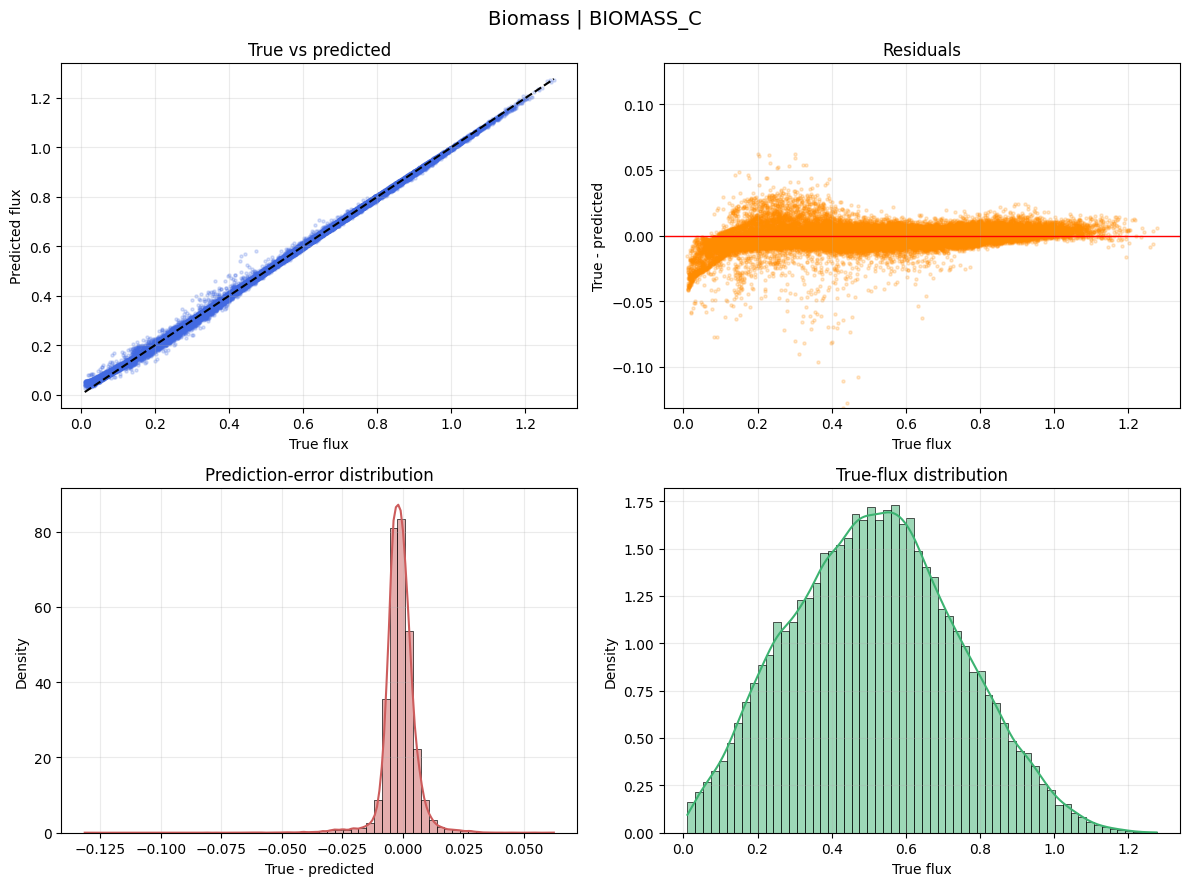

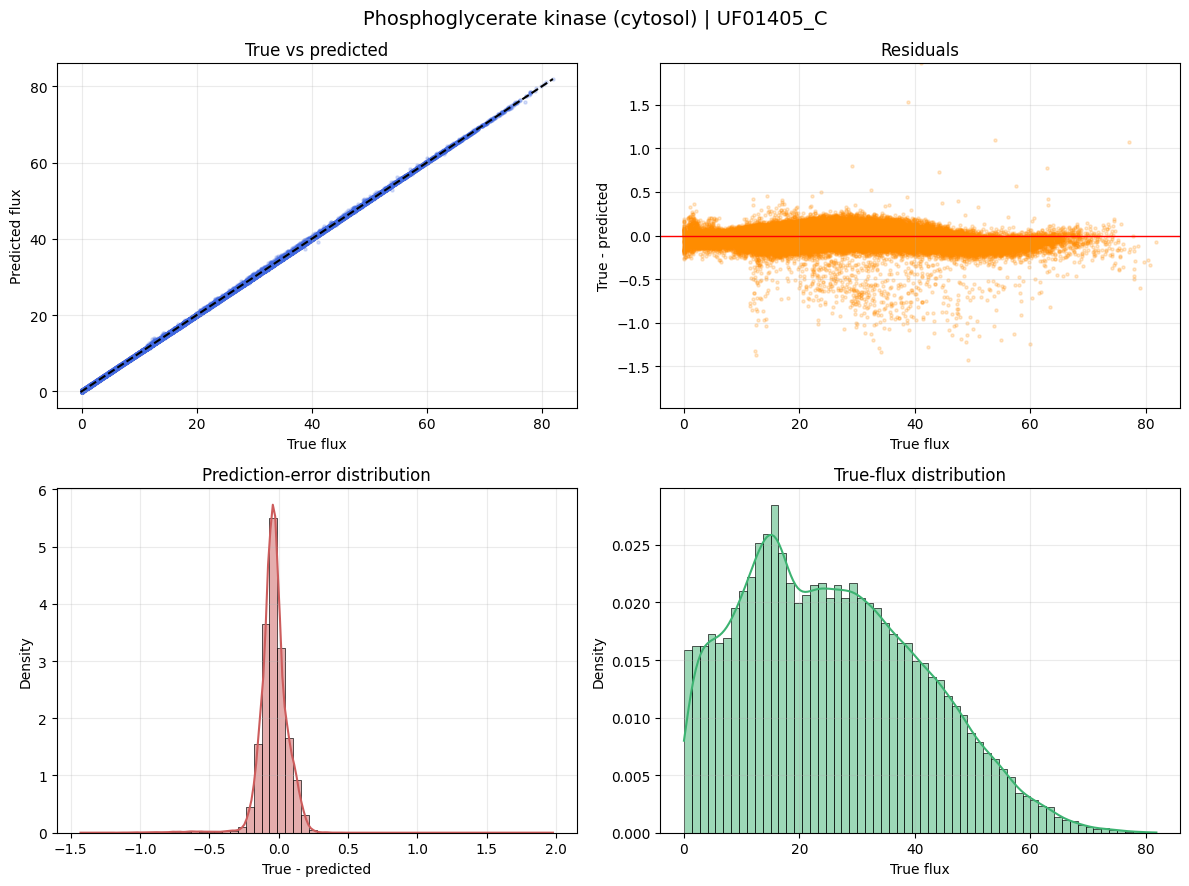

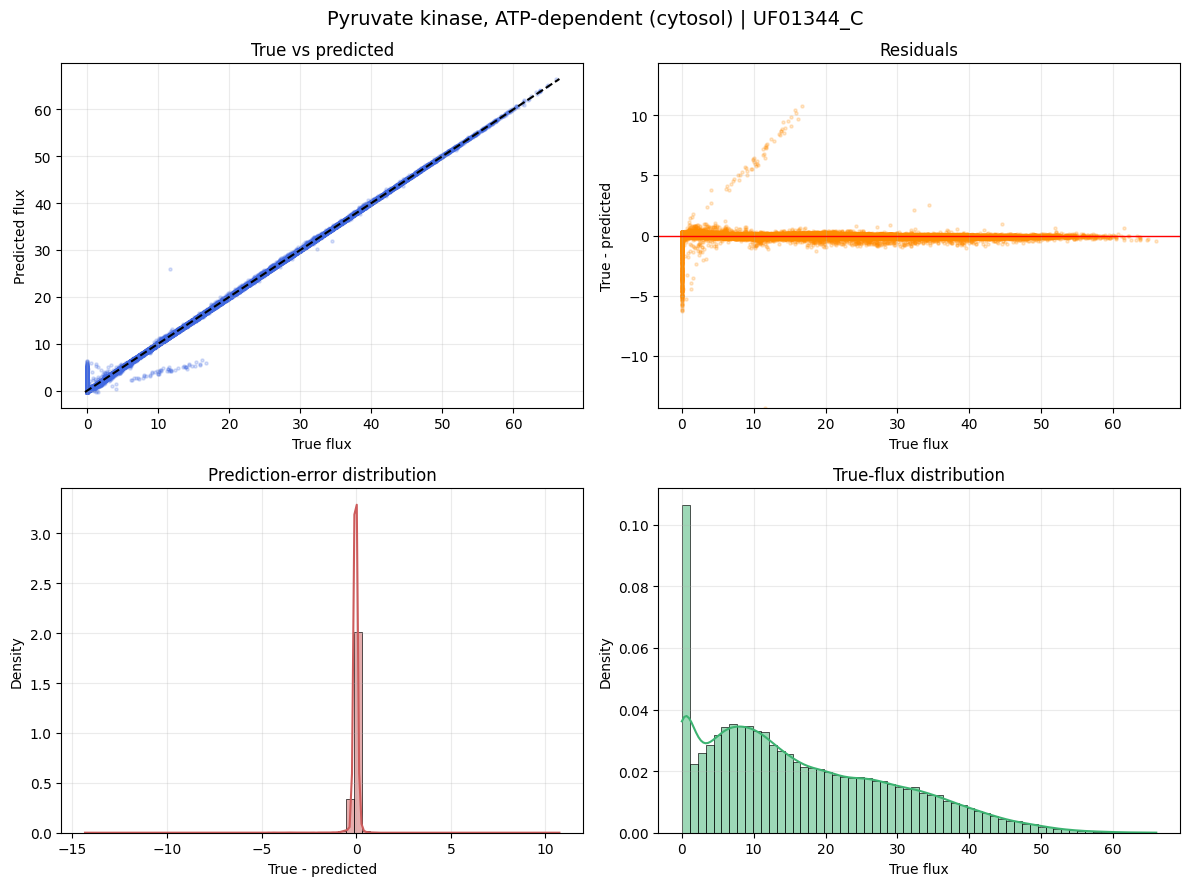

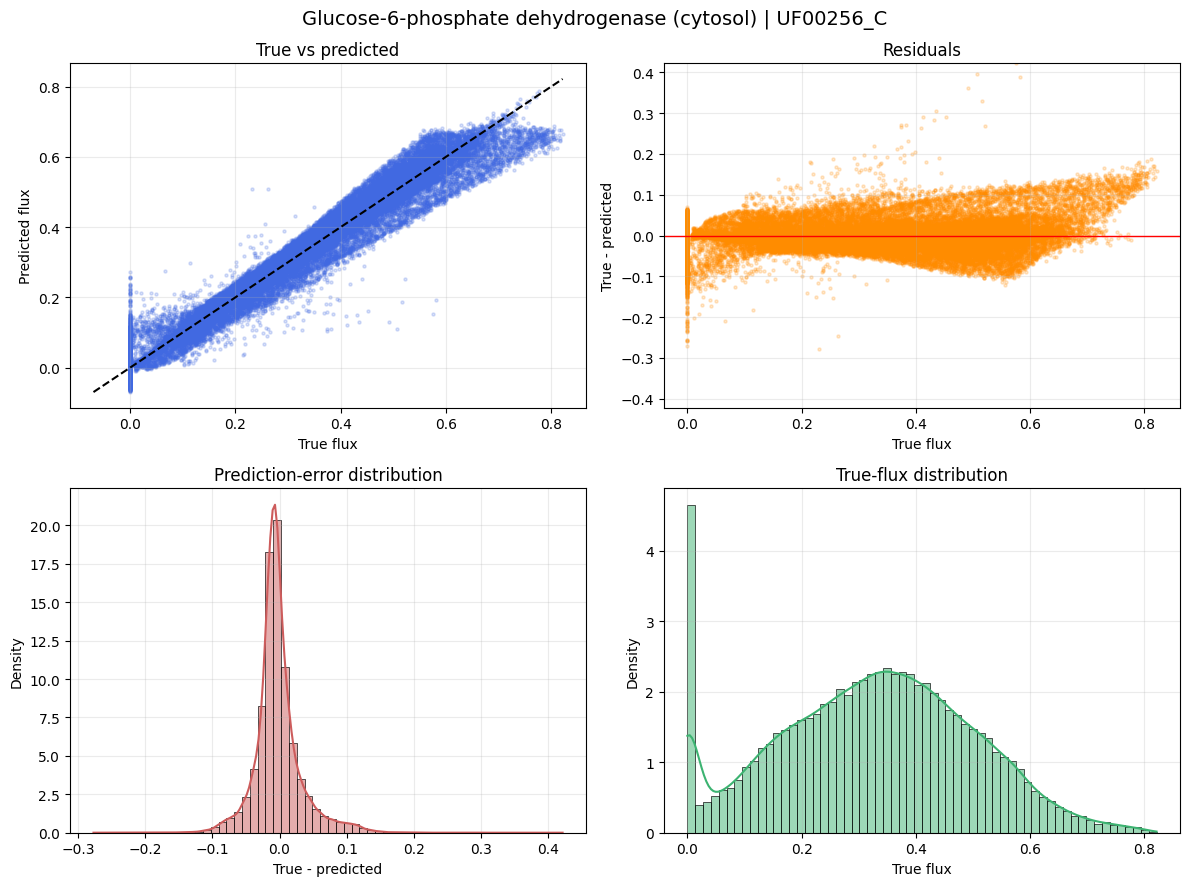

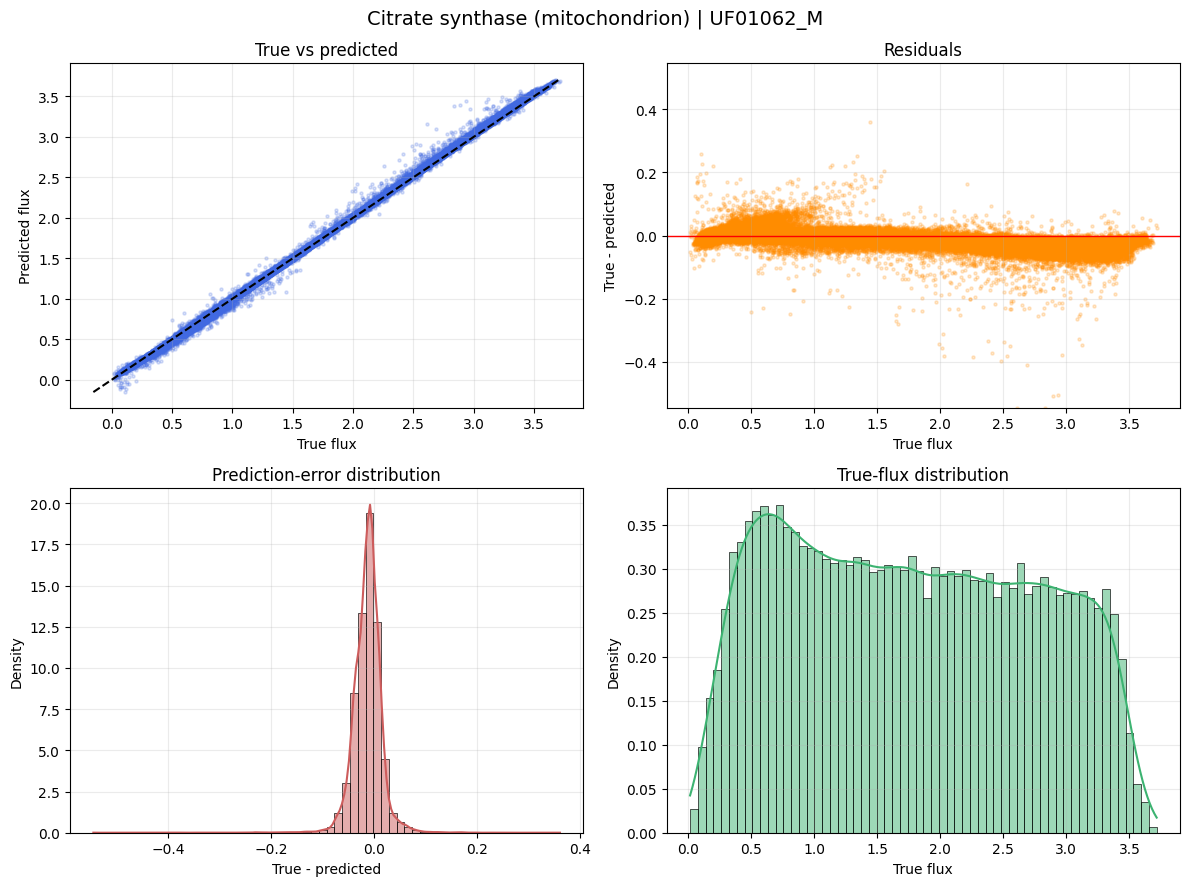

In [6]:
def plot_diagnostics_2x2(y_true, y_pred, label, save_path=None):
    residuals = y_true - y_pred
    max_error = max(float(np.abs(residuals).max()), np.finfo(float).eps)
    lo, hi = min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())
    if lo == hi:
        padding = max(abs(float(lo)) * 0.05, 0.01)
        lo, hi = lo - padding, hi + padding
    fig, axes = plt.subplots(2, 2, figsize=(12, 9))
    axes[0, 0].scatter(y_true, y_pred, s=5, alpha=0.2, color="royalblue", rasterized=True)
    axes[0, 0].plot([lo, hi], [lo, hi], "k--", lw=1.5)
    axes[0, 0].set(title="True vs predicted", xlabel="True flux", ylabel="Predicted flux")
    axes[0, 1].scatter(y_true, residuals, s=5, alpha=0.2, color="darkorange", rasterized=True)
    axes[0, 1].axhline(0, color="red", lw=1)
    axes[0, 1].set(title="Residuals", xlabel="True flux", ylabel="True - predicted",
                   ylim=(-max_error, max_error))
    sns.histplot(residuals, bins=60, kde=bool(np.ptp(residuals) > 0), stat="density",
                 color="indianred", ax=axes[1, 0])
    axes[1, 0].set(title="Prediction-error distribution", xlabel="True - predicted", ylabel="Density")
    sns.histplot(y_true, bins=60, kde=bool(np.ptp(y_true) > 0), stat="density",
                 color="mediumseagreen", ax=axes[1, 1])
    axes[1, 1].set(title="True-flux distribution", xlabel="True flux", ylabel="Density")
    for ax in axes.ravel():
        ax.grid(True, alpha=0.25)
    fig.suptitle(label, fontsize=14)
    fig.tight_layout()
    if save_path is not None:
        save_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

for column, (flux_name, description) in enumerate(diagnostic_fluxes.items()):
    save_path = pic_dir / f"{model_name}_{flux_name}_diagnostics.png" if SAVE_PLOTS else None
    plot_diagnostics_2x2(
        diagnostic_y_true[:, column], diagnostic_y_pred[:, column],
        label=f"{description} | {flux_name.removesuffix('_flux')}", save_path=save_path,
    )

## Overall pooled metrics

Pool every sample–reaction pair into one evaluation population, including the 17 injected exchange slots. These are **not averages of per-reaction metrics** and are computed in the original signed flux scale. Higher-magnitude fluxes influence pooled R²/RMSE more strongly. The training loss excludes injected tokens; this requested overall evaluation includes them.

In [7]:
# Pooled simulated metrics across every test sample and all 1,971 flux outputs.
n_values = pooled_stats["n_values"]
overall_mae = pooled_stats["absolute_error_sum"] / n_values
overall_rmse = np.sqrt(pooled_stats["squared_error_sum"] / n_values)
total_sum_squares = max(
    0.0, pooled_stats["true_square_sum"] - pooled_stats["true_sum"] ** 2 / n_values
)
if total_sum_squares > 0:
    overall_r2 = 1.0 - pooled_stats["squared_error_sum"] / total_sum_squares
else:
    overall_r2 = 1.0 if pooled_stats["squared_error_sum"] == 0 else 0.0
pooled_metrics = {"R2": float(overall_r2), "MAE": float(overall_mae), "RMSE": float(overall_rmse)}
print(f"Overall pooled metrics: {pooled_stats['n_rows']:,} samples × {len(outputs):,} fluxes")
print(f"R²   : {overall_r2:.6f}")
print(f"MAE  : {overall_mae:.6f}")
print(f"RMSE : {overall_rmse:.6f}")

Overall pooled metrics: 50,000 samples × 1,971 fluxes
R²   : 0.999908
MAE  : 0.005744
RMSE : 0.027953


## Predict measured Candida growth

Here we test whether the simulated metabolic model helps predict **experimental growth**. We use all 29 Candida intermedia C04520 conditions and their `growth_max_sandra` values, including the two whose original growth fits failed. The target's units and processing still need confirmation.

Run the setup and model-loading cells above first; the simulated prediction cells can be skipped.

We compare a training-set mean, ridge regression, a direct MLP, and two MLP + frozen FluxFormer models. One hybrid sees the eight carbon compounds; the other sees all 25 measured chemicals. The extra chemicals can influence learned uptake bounds, even when they have no model exchange.

In [8]:
from copy import deepcopy
import re

from IPython.display import display
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import LeaveOneGroupOut, LeaveOneOut, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from torch import nn

from generate_candida_intermedia_data import (
    BASAL_EXCHANGES, CARBON_EXCHANGES, OXYGEN_EXCHANGE, parse_args,
    solve_medium, validate_model,
)

GROWTH_CSV = Path('metabolic_models/Growth_data_for_ML_Helsinki_Uni.csv')
GROWTH_TARGET = 'growth_max_sandra'
GROWTH_SETTINGS = dict(hidden=(256, 128), dropout=0.1, learning_rate=1e-3,
                       weight_decay=1e-3, epochs=200, patience=25,
                       min_delta=1e-7, batch_size=4, inner_fraction=0.2, seed=42)
RUN_GROUPED_CV = False  # Optional second evaluation; roughly doubles hybrid training time.
growth_dir = Path('insights/candida_growth') / model_name

### Experimental data

Predictors contain medium chemistry only; other growth measurements are excluded. Original fit failures are shown as flags and do not remove any Sandra values. Temperature and time describe pretreatment and are left out of this first comparison.

In [9]:
growth = pd.read_csv(GROWTH_CSV)
growth = growth.loc[growth['organism_id'].eq('Candida intermedia_C04520')].reset_index(drop=True)
response_columns = ['AUC', 'NetAUC_sandra', 'AUC_sandra', 'growth_max',
                    'growth_max_sandra', 'Biomass', 'Net_Biomass', 'Relative_control']
excluded_columns = ['organism_id', 'medium_id', 'Temperature', 'Time', 'Dilution', *response_columns]
chemical_features = [name for name in growth.columns if name not in excluded_columns]
carbon_features = list(CARBON_EXCHANGES)
growth_y = pd.to_numeric(growth[GROWTH_TARGET], errors='raise').to_numpy(np.float32)
growth['original_fit_failed'] = growth['growth_max'].eq('cannot fit data')
if len(growth) != 29 or growth['medium_id'].nunique() != 29 or len(chemical_features) != 25:
    raise ValueError('Expected 29 distinct Candida conditions and 25 chemical features.')
chemistry = growth[chemical_features].to_numpy(np.float32)
if not np.isfinite(chemistry).all() or (chemistry < 0).any() or not np.isfinite(growth_y).all():
    raise ValueError('Expected finite nonnegative chemistry and finite Sandra targets.')
# Masks use original concentrations, so standardization cannot change source presence.
growth_presence = np.column_stack([
    growth[carbon_features].to_numpy() > 0, np.ones(len(growth), dtype=bool),
]).astype(np.float32)
if input_cols != list(INPUT_EXCHANGES):
    raise ValueError('Load the current 17-input Candida checkpoint before this section.')
model.eval().requires_grad_(False)
display(growth[['medium_id', GROWTH_TARGET, 'original_fit_failed']])
print(f'All {len(growth)} Sandra targets retained; {len(carbon_features)} carbon and {len(chemical_features)} chemistry features.')

,medium_id,growth_max_sandra,original_fit_failed
0,"Medium 1 (wheat straw 170, 10)",0.082,False
1,"Medium 2(wheat straw 190, 10)",0.018,False
2,"Medium 3 (wheat straw 200, 10)",0.045,False
3,"Medium 4(wheat straw 200, 10 / 2x)",0.094,False
4,Medium 5(oat straw 170 10),0.069,False
5,Medium 6(oat straw 190 10),0.046,False
6,"Medium 7(oat straw 200, 10)",0.052,False
7,"Medium 8(wheat bran 170, 10)",0.076,False
8,"Medium 9(wheat bran 170, 10/ 2x)",0.140,False
9,"Medium 10(wheat bran 170, 5)",0.068,False


All 29 Sandra targets retained; 8 carbon and 25 chemistry features.


### Models

All MLPs have hidden layers of **256 and 128 units**. In the hybrids, the MLP learns eight carbon uptake magnitudes and oxygen. These become negative exchange bounds for the frozen FluxFormer, whose biomass output predicts growth.

Recorded zero carbon concentrations close the corresponding uptake as a working assumption. Oxygen is learned; basal bounds stay at −1000. Learned uptake magnitudes have no upper ceiling. The full-chemistry model can learn predictive associations with other chemicals, but this does not identify inhibition mechanisms.

In [10]:
class CandidaGrowthMLP(nn.Module):
    def __init__(self, n_features, reservoir=None):
        super().__init__()
        self.reservoir = reservoir
        h1, h2 = GROWTH_SETTINGS['hidden']
        self.front = nn.Sequential(
            nn.Linear(n_features, h1), nn.ReLU(), nn.Dropout(GROWTH_SETTINGS['dropout']),
            nn.Linear(h1, h2), nn.ReLU(), nn.Linear(h2, 9 if reservoir is not None else 1),
        )
        if reservoir is not None:
            reservoir.requires_grad_(False).eval()
            controlled = [*CARBON_EXCHANGES.values(), OXYGEN_EXCHANGE]
            required = [*BASAL_EXCHANGES, *controlled]
            expected = [outputs.index(f'{rid}_flux') for rid in INPUT_EXCHANGES]
            if reservoir.input_token_indices.tolist() != expected:
                raise ValueError('Candida input token order differs from the reservoir.')
            if set(required) != set(INPUT_EXCHANGES):
                raise ValueError('Review the Candida basal/carbon/oxygen mapping.')
            fixed = torch.zeros(len(outputs))
            fixed[[outputs.index(f'{rid}_flux') for rid in BASAL_EXCHANGES]] = -1000.0
            self.register_buffer('fixed', fixed)
            self.register_buffer('controlled', torch.tensor([outputs.index(f'{rid}_flux') for rid in controlled]))
            self.biomass_index = outputs.index('BIOMASS_C_flux')

    def train(self, mode=True):
        super().train(mode)
        if self.reservoir is not None:
            self.reservoir.eval()
        return self

    def forward(self, x, presence):
        raw = self.front(x)
        if self.reservoir is None:
            return raw[:, 0], None
        rates = nn.functional.softplus(raw) * presence
        tokens = self.fixed.expand(len(x), -1).clone()
        tokens[:, self.controlled] = -rates
        prediction, _ = self.reservoir(tokens.unsqueeze(-1), output_subset=None)
        return prediction[:, self.biomass_index, -1], rates


def predict_growth_mlp(network, x, presence):
    network.eval()
    predictions, contexts = [], []
    with torch.no_grad():
        for start in range(0, len(x), GROWTH_SETTINGS['batch_size']):
            stop = start + GROWTH_SETTINGS['batch_size']
            prediction, rates = network(torch.as_tensor(x[start:stop], dtype=torch.float32, device=device),
                                        torch.as_tensor(presence[start:stop], dtype=torch.float32, device=device))
            predictions.append(prediction.cpu().numpy())
            if rates is not None:
                contexts.append(rates.cpu().numpy())
    predicted = np.concatenate(predictions)
    if not np.isfinite(predicted).all():
        raise FloatingPointError('Nonfinite experimental growth predictions.')
    return predicted, np.concatenate(contexts) if contexts else None

### Training without using the test answer

Each leave-one-out fold holds one condition aside. We choose the stopping epoch using an inner 80/20 split of the other 28, then train a fresh MLP on all 28 for that many epochs. Scaling is fitted on the training rows each time. Ridge strength is also chosen on the inner split.

The held-out Sandra value is used only to score the final prediction. MLPs minimize squared growth error; FluxFormer weights stay frozen while gradients pass through to the front MLP.

In [11]:
def fit_growth_mlp(x, y, presence, train_ids, validation_ids=None, epochs=None, hybrid=False, seed=42):
    train_ids = np.asarray(train_ids)
    if validation_ids is not None and np.intersect1d(train_ids, validation_ids).size:
        raise ValueError('Training and validation rows overlap.')
    torch.manual_seed(seed)
    scaler = StandardScaler().fit(x[train_ids])
    scaled = torch.as_tensor(scaler.transform(x), dtype=torch.float32, device=device)
    target = torch.as_tensor(y, dtype=torch.float32, device=device)
    mask = torch.as_tensor(presence, dtype=torch.float32, device=device)
    network = CandidaGrowthMLP(x.shape[1], model if hybrid else None).to(device)
    optimizer = torch.optim.AdamW(network.front.parameters(), lr=GROWTH_SETTINGS['learning_rate'],
                                 weight_decay=GROWTH_SETTINGS['weight_decay'])
    max_epochs = GROWTH_SETTINGS['epochs'] if epochs is None else int(epochs)
    best_loss, best_epoch, stale, best_state = float('inf'), 0, 0, None
    history = []
    for epoch in range(max_epochs):
        network.train()
        running = 0.0
        order = train_ids[torch.randperm(len(train_ids)).numpy()]
        for start in range(0, len(order), GROWTH_SETTINGS['batch_size']):
            rows = order[start:start + GROWTH_SETTINGS['batch_size']]
            optimizer.zero_grad(set_to_none=True)
            prediction, _ = network(scaled[rows], mask[rows])
            loss = nn.functional.mse_loss(prediction, target[rows])
            if not torch.isfinite(loss):
                raise FloatingPointError('Nonfinite growth-training loss.')
            loss.backward()
            nn.utils.clip_grad_norm_(network.front.parameters(), 1.0, error_if_nonfinite=True)
            optimizer.step()
            running += loss.item() * len(rows)
        record = dict(epoch=epoch + 1, training_loss=running / len(train_ids))
        if validation_ids is not None:
            predicted, _ = predict_growth_mlp(network, scaler.transform(x[validation_ids]), presence[validation_ids])
            validation_loss = float(mean_squared_error(y[validation_ids], predicted))
            record['validation_loss'] = validation_loss
            if validation_loss < best_loss - GROWTH_SETTINGS['min_delta']:
                best_loss, best_epoch, stale = validation_loss, epoch + 1, 0
                best_state = deepcopy(network.front.state_dict())
            else:
                stale += 1
        history.append(record)
        if validation_ids is not None and stale >= GROWTH_SETTINGS['patience']:
            break
    if validation_ids is not None:
        if best_state is None:
            raise FloatingPointError('No finite inner-validation checkpoint.')
        network.front.load_state_dict(best_state)
    else:
        best_epoch = max_epochs
    return network, scaler, best_epoch, history


def growth_metrics(truth, prediction):
    return dict(R2=r2_score(truth, prediction), MAE=mean_absolute_error(truth, prediction),
                RMSE=np.sqrt(mean_squared_error(truth, prediction)))

In [12]:
def run_growth_cv(splits, name, save=True):
    methods = {'Direct MLP': (chemical_features, False),
               'FluxFormer + nutrients': (carbon_features, True),
               'FluxFormer + chemistry': (chemical_features, True)}
    prediction_rows, context_rows, selection_rows, histories, folds = [], [], [], [], []
    splits = list(splits)
    for fold, (train, test) in enumerate(splits):
        train, test = np.asarray(train), np.asarray(test)
        if np.intersect1d(train, test).size:
            raise ValueError('Outer training and test rows overlap.')
        seed = GROWTH_SETTINGS['seed'] + fold
        inner_train, inner_val = train_test_split(train, test_size=GROWTH_SETTINGS['inner_fraction'], random_state=seed)
        folds.append(dict(fold=fold, train=train.tolist(), test=test.tolist(),
                          inner_train=inner_train.tolist(), inner_validation=inner_val.tolist(), seed=seed))
        predictions = {'Training mean': np.repeat(growth_y[train].mean(), len(test))}
        x = growth[chemical_features].to_numpy(np.float32)
        ridge_losses = {}
        for alpha in (0.01, 0.1, 1.0, 10.0, 100.0):
            ridge = make_pipeline(StandardScaler(), Ridge(alpha=alpha)).fit(x[inner_train], growth_y[inner_train])
            ridge_losses[alpha] = mean_squared_error(growth_y[inner_val], ridge.predict(x[inner_val]))
        alpha = min(ridge_losses, key=ridge_losses.get)
        ridge = make_pipeline(StandardScaler(), Ridge(alpha=alpha)).fit(x[train], growth_y[train])
        predictions['Ridge'] = ridge.predict(x[test])
        selection_rows.append(dict(fold=fold, method='Ridge', alpha=alpha))
        for method, (features, hybrid) in methods.items():
            x = growth[features].to_numpy(np.float32)
            selected, _, epochs, history = fit_growth_mlp(
                x, growth_y, growth_presence, inner_train, inner_val, hybrid=hybrid, seed=seed)
            del selected
            network, scaler, _, refit_history = fit_growth_mlp(
                x, growth_y, growth_presence, train, epochs=epochs, hybrid=hybrid, seed=seed)
            predicted, rates = predict_growth_mlp(network, scaler.transform(x[test]), growth_presence[test])
            predictions[method] = predicted
            selection_rows.append(dict(fold=fold, method=method, epochs=epochs))
            for phase, records in [('selection', history), ('refit', refit_history)]:
                histories.extend(dict(fold=fold, method=method, phase=phase, **record) for record in records)
            if rates is not None:
                for row, values in zip(test, rates):
                    context_rows.append(dict(row=int(row), fold=fold, method=method,
                                             **dict(zip([*carbon_features, 'oxygen'], values.astype(float)))))
            del network
        for method, predicted in predictions.items():
            for row, value in zip(test, predicted):
                prediction_rows.append(dict(row=int(row), fold=fold, medium_id=growth.loc[row, 'medium_id'],
                    method=method, truth=float(growth_y[row]), prediction=float(value),
                    original_fit_failed=bool(growth.loc[row, 'original_fit_failed'])))
        print(f'{name}: fold {fold + 1}/{len(splits)} complete', flush=True)
    predictions = pd.DataFrame(prediction_rows)
    if len(predictions) != 5 * len(growth) or not predictions.groupby(['method', 'row']).size().eq(1).all():
        raise ValueError('Each method must predict every experimental row exactly once.')
    if not np.isfinite(predictions['prediction']).all():
        raise FloatingPointError('Incomplete or nonfinite held-out predictions.')
    metrics = pd.DataFrame([dict(method=method, **growth_metrics(part.truth, part.prediction))
                            for method, part in predictions.groupby('method', sort=False)]).set_index('method')
    contexts = pd.DataFrame(context_rows)
    selection, training_history = pd.DataFrame(selection_rows), pd.DataFrame(histories)
    if save:
        destination = growth_dir / name
        destination.mkdir(parents=True, exist_ok=True)
        for filename, frame in [('predictions', predictions), ('uptake_bounds', contexts),
                                ('selection', selection), ('training_history', training_history)]:
            frame.to_csv(destination / f'{filename}.csv', index=False)
        metrics.to_csv(destination / 'metrics.csv')
        provenance = dict(checkpoint=str(CHECKPOINT_PATH), checkpoint_sha256=file_sha256(CHECKPOINT_PATH),
            experimental_csv=str(GROWTH_CSV), experimental_csv_sha256=file_sha256(GROWTH_CSV),
            metabolic_model=str(MODEL_PATH), metabolic_model_sha256=file_sha256(MODEL_PATH),
            torch_version=str(torch.__version__), device=str(device),
            target=GROWTH_TARGET, settings=GROWTH_SETTINGS, n_conditions=len(growth),
            feature_sets={'Training mean': [], 'Ridge': chemical_features,
                          **{key: value[0] for key, value in methods.items()}},
            input_columns=input_cols, output_columns=outputs, folds=folds)
        (destination / 'provenance.json').write_text(json.dumps(provenance, indent=2), encoding='utf-8')
    return dict(predictions=predictions, metrics=metrics, contexts=contexts,
                selection=selection, history=training_history, folds=folds)

### Leave-one-out results

Run this cell to train and evaluate all five methods. This is the main experiment and can take substantial time because the hybrids backpropagate through the full reaction vocabulary.

Each condition receives one prediction made without its growth value. The table pools all 29 held-out predictions; larger R² and smaller MAE/RMSE indicate better performance. Results and the exact fold settings are saved under `insights/candida_growth/`.

In [13]:
growth_loo = run_growth_cv(LeaveOneOut().split(growth), 'loo')
display(growth_loo['metrics'].round(6))

loo: fold 1/29 complete
loo: fold 2/29 complete
loo: fold 3/29 complete
loo: fold 4/29 complete
loo: fold 5/29 complete
loo: fold 6/29 complete
loo: fold 7/29 complete
loo: fold 8/29 complete
loo: fold 9/29 complete
loo: fold 10/29 complete
loo: fold 11/29 complete
loo: fold 12/29 complete
loo: fold 13/29 complete
loo: fold 14/29 complete
loo: fold 15/29 complete
loo: fold 16/29 complete
loo: fold 17/29 complete
loo: fold 18/29 complete
loo: fold 19/29 complete
loo: fold 20/29 complete
loo: fold 21/29 complete
loo: fold 22/29 complete
loo: fold 23/29 complete
loo: fold 24/29 complete
loo: fold 25/29 complete
loo: fold 26/29 complete
loo: fold 27/29 complete
loo: fold 28/29 complete
loo: fold 29/29 complete


,R2,MAE,RMSE
method,,,
Training mean,-0.072704,0.064158,0.079877
Ridge,0.481552,0.037188,0.055531
Direct MLP,0.584399,0.040423,0.049719
FluxFormer + nutrients,0.275479,0.045400,0.065646
FluxFormer + chemistry,0.635330,0.035898,0.046573


### Where do predictions succeed or fail?

Each point below is a held-out medium. Points close to the dashed line are accurate. Crosses mark the original fit failures, which remain included. The error plot compares the two hybrids across all media.

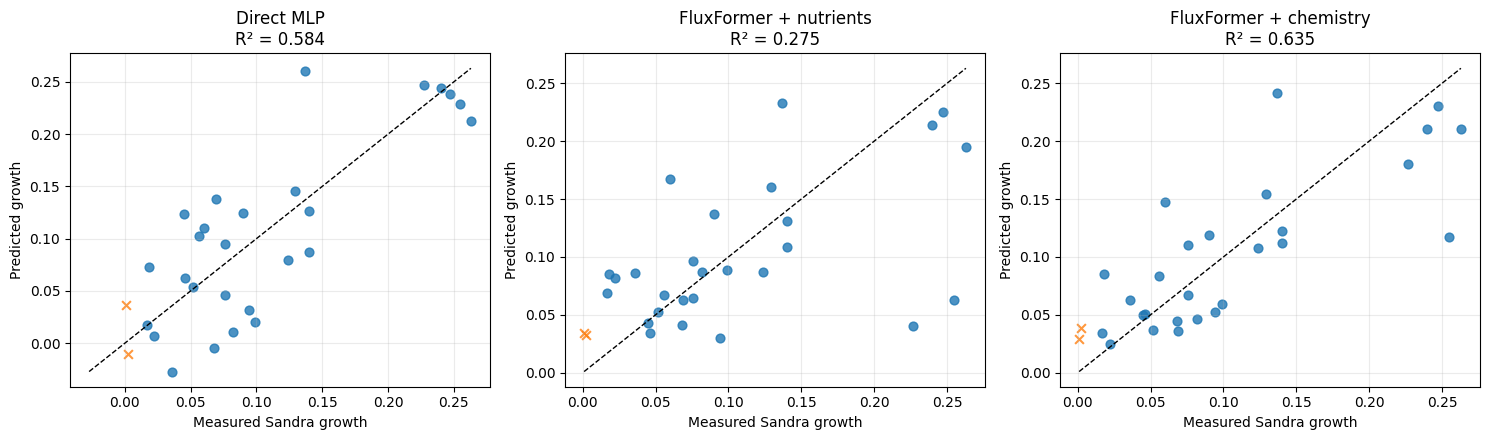

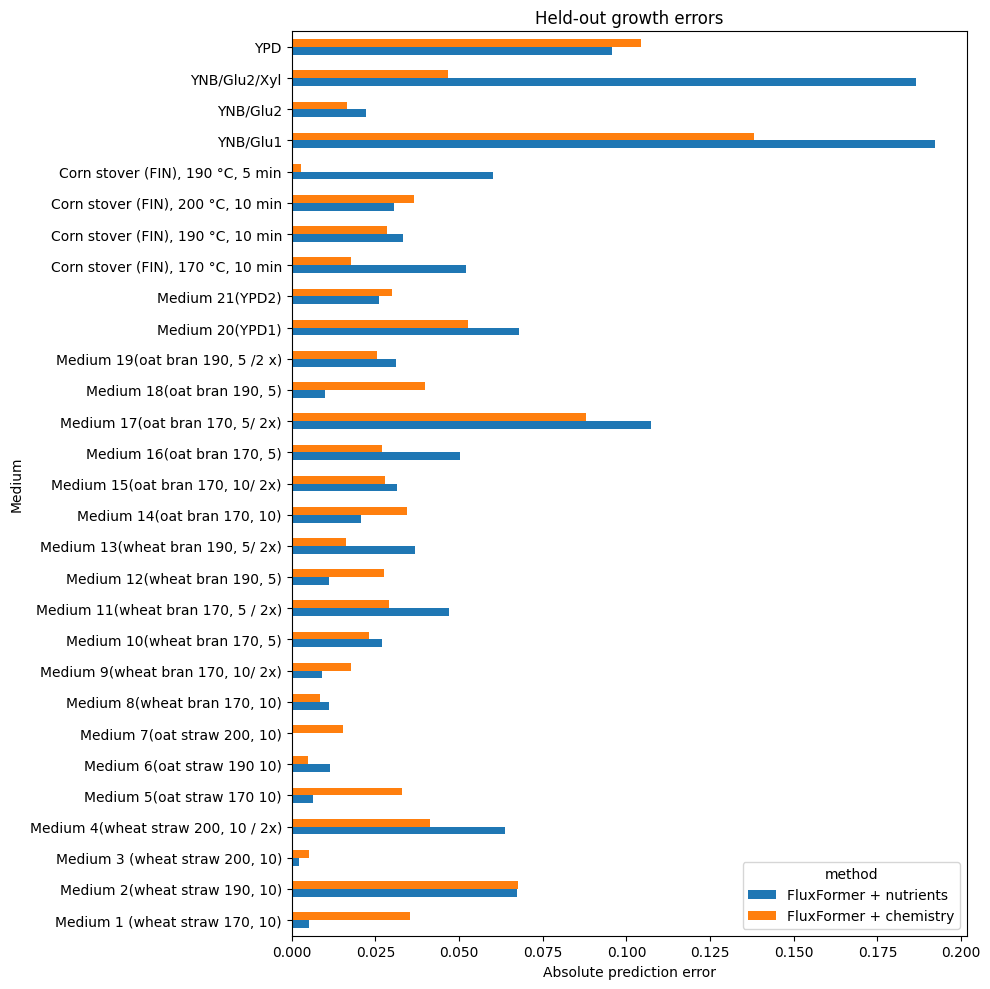

In [14]:
growth_methods = ['Direct MLP', 'FluxFormer + nutrients', 'FluxFormer + chemistry']
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, method in zip(axes, growth_methods):
    part = growth_loo['predictions'].query('method == @method')
    lo = min(part.truth.min(), part.prediction.min())
    hi = max(part.truth.max(), part.prediction.max())
    for failed, marker in [(False, 'o'), (True, 'x')]:
        points = part.loc[part.original_fit_failed.eq(failed)]
        ax.scatter(points.truth, points.prediction, marker=marker, s=40, alpha=0.8)
    ax.plot([lo, hi], [lo, hi], 'k--', lw=1)
    ax.set(title=f"{method}\nR² = {growth_loo['metrics'].loc[method, 'R2']:.3f}",
           xlabel='Measured Sandra growth', ylabel='Predicted growth')
    ax.grid(alpha=0.25)
fig.tight_layout()
if SAVE_PLOTS:
    pic_dir.mkdir(parents=True, exist_ok=True)
    fig.savefig(pic_dir / 'candida_growth_loo.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)

errors = growth_loo['predictions'].assign(absolute_error=lambda frame: abs(frame.prediction - frame.truth))
error_table = errors.pivot(index='medium_id', columns='method', values='absolute_error').reindex(growth.medium_id)
ax = error_table[['FluxFormer + nutrients', 'FluxFormer + chemistry']].plot.barh(figsize=(10, 10))
ax.set(xlabel='Absolute prediction error', ylabel='Medium', title='Held-out growth errors')
ax.figure.tight_layout()
plt.show()
plt.close(ax.figure)

### Check the learned uptake bounds

These values are fitted uptake capacities, not measured consumption rates. The surrogate was trained with selected carbon and oxygen magnitudes from 0.1 to 10; values outside that range indicate extrapolation. Zero bounds for unselected carbon compounds are expected.

In [15]:
learned_bounds = growth_loo['contexts'].query("method == 'FluxFormer + chemistry'").set_index('row').sort_index()
bound_values = learned_bounds[[*carbon_features, 'oxygen']].to_numpy()
outside_training = (((bound_values < 0.1) | (bound_values > 10)) & growth_presence.astype(bool))
display(learned_bounds[[*carbon_features, 'oxygen']].describe().loc[['min', 'mean', 'max']].round(4))
print(f'{outside_training.any(axis=1).sum()} / {len(growth)} conditions have learned bounds outside the sampled training range.')

,arabinose,glucose,galactose,xylose,manose,fructose,lactate,acetate,oxygen
min,0.0000,0.0718,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0334
mean,0.6111,0.9570,0.3408,0.2199,0.1659,0.1862,0.5518,0.2190,1.2609
max,1.3361,2.6782,1.0275,0.6436,0.6812,0.5832,2.5790,0.8332,4.2468


3 / 29 conditions have learned bounds outside the sampled training range.


### Does actual pFBA agree at the learned bounds?

Check up to five held-out conditions, including the largest experimental errors and the lowest/highest predicted growth. We solve pFBA using exactly the learned bounds and the original basal policy. Agreement with FluxFormer tests surrogate fidelity at those bounds; agreement with measured growth tests experimental transfer.

In [16]:
from cobra.io import read_sbml_model

reaction_ids = [name.removesuffix('_flux') for name in outputs]
hybrid_oof = growth_loo['predictions'].query("method == 'FluxFormer + chemistry'").set_index('row')
largest_errors = (hybrid_oof.prediction - hybrid_oof.truth).abs().nlargest(3).index.tolist()
check_rows = list(dict.fromkeys([*largest_errors, hybrid_oof.prediction.idxmin(), hybrid_oof.prediction.idxmax()]))
pfba_model = read_sbml_model(str(MODEL_PATH))
validate_model(pfba_model)
pfba_args = parse_args(['--dataset', 'test', '--flux-solver-mode', 'pfba',
                        '--pfba-fraction-of-optimum', '0.999'])
pfba_rows = []
with pfba_model:
    pfba_model.medium = {}
    for row in check_rows:
        bounds = dict.fromkeys(BASAL_EXCHANGES, -1000.0)
        bounds.update({rid: -float(learned_bounds.loc[row, name]) for name, rid in CARBON_EXCHANGES.items()})
        bounds[OXYGEN_EXCHANGE] = -float(learned_bounds.loc[row, 'oxygen'])
        fluxes, status = solve_medium(pfba_model, bounds, reaction_ids, pfba_args)
        pfba_growth = float(fluxes[reaction_ids.index('BIOMASS_C')]) if fluxes is not None else np.nan
        pfba_rows.append(dict(medium_id=growth.loc[row, 'medium_id'], measured=float(growth_y[row]),
            FluxFormer=float(hybrid_oof.loc[row, 'prediction']), pFBA=pfba_growth, status=status))
pfba_check = pd.DataFrame(pfba_rows)
pfba_check['surrogate_absolute_error'] = abs(pfba_check.FluxFormer - pfba_check.pFBA)
display(pfba_check)
(growth_dir / 'loo').mkdir(parents=True, exist_ok=True)
pfba_check.to_csv(growth_dir / 'loo/pfba_check.csv', index=False)

,medium_id,measured,FluxFormer,pFBA,status,surrogate_absolute_error
0,YNB/Glu1,0.255,0.116852,0.112003,optimal,0.004849
1,YPD,0.137,0.241320,0.250644,optimal,0.009324
2,"Medium 17(oat bran 170, 5/ 2x)",0.060,0.147917,0.145208,optimal,0.002709
3,"Corn stover (FIN), 190 °C, 5 min",0.022,0.024688,0.012215,optimal,0.012473


### Optional: hold out related media together

Ordinary LOO can leave a diluted version of the test medium in training. This second evaluation holds each original/diluted pair out together; other media stay separate. Set `RUN_GROUPED_CV = True` above to run it. All 29 conditions still receive predictions.

In [17]:
def growth_medium_group(name):
    name = re.sub(r'^Medium\s+\d+\s*', '', name)
    name = re.sub(r'/\s*2\s*x', '', name, flags=re.IGNORECASE)
    return re.sub(r'[\s,()]+', ' ', name).strip()


medium_groups = growth['medium_id'].map(growth_medium_group).to_numpy()
if RUN_GROUPED_CV:
    growth_grouped = run_growth_cv(LeaveOneGroupOut().split(growth, groups=medium_groups), 'grouped')
    display(pd.concat({'LOO': growth_loo['metrics'], 'Grouped': growth_grouped['metrics']}).round(6))
else:
    print(f'Grouped evaluation ready: {len(np.unique(medium_groups))} groups; set RUN_GROUPED_CV = True to run.')

Grouped evaluation ready: 22 groups; set RUN_GROUPED_CV = True to run.
